# oligo-mtDBS: cellcharter compartment analysis

References for the analyses:
https://github.com/CSOgroup/cellcharter_analyses/blob/main/codex_mouse_spleen.ipynb

In [1]:
# load the libraries
from matplotlib import cm
import anndata as ad
import squidpy as sq
import cellcharter as cc
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import matplotlib.patches as mpatches
import math
print("All imports successful!")

/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


All imports successful!


In [2]:
import logging
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)

In [2]:
adata = ad.read_h5ad('../data/mtDNA_DSB_5k_clustered_annotation_MANA.h5ad')

## Inspecting the object

In [4]:
print("Number of spots/cells:", adata.n_obs)
print("Number of genes:", adata.n_vars)

print("Shape:", adata.shape)

Number of spots/cells: 980474
Number of genes: 250
Shape: (980474, 250)


In [5]:
print(adata)
print("\nObservation metadata:")
print(adata.obs.shape)

print("\nGene metadata:")
print(adata.var.shape)

print("\nAvailable dimensionality reductions and other embeddings:")
print(list(adata.obsm.keys()))

print("\nAvailable layers:")
print(list(adata.layers.keys()))

print("\nAvailable pairwise matrices:")
print(list(adata.obsp.keys()))

print("\nUnstructured metadata:")
print(list(adata.uns.keys()))

AnnData object with n_obs × n_vars = 980474 × 250
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'run', 'n_genes_by_counts', 'n_counts', 'n_genes', 'leiden_0.5', 'leiden_1', 'leiden_2', 'cell_class', 'sample_id', 'age', 'sex', 'genotype', 'condition', 'cell_type', 'cell_id', 'rbd_domain_0.1', 'rbd_domain_0.2', 'rbd_domain_0.5', 'rbd_domain_1.0', 'RBD_compartment', 'RBD_compartment_simplified', 'leiden_1.5', 'leiden_2.1', 'leiden_2.3', 'leiden_2.5', 'leiden_3', 'cytetype_annotation_leiden_3', 'cytetype_cellOntologyTerm_leiden_3', 'novae_sid', 'neighborhood_valid', 'novae_leaves', 'novae_domains_15', 'novae_domains_30', 'novae_domains_25', 'novae_domains_20', 'novae_domains_50', '_scvi_batch', '_scvi_labels', 'leiden_mana_0.5', 'leiden_mana_0.1', 'cell_class_

In [6]:
adata.obs.head()

,x_centroid,y_centroid,transcript_counts,control_probe_counts,genomic_control_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,...,novae_domains_15,novae_domains_30,novae_domains_25,novae_domains_20,novae_domains_50,_scvi_batch,_scvi_labels,leiden_mana_0.5,leiden_mana_0.1,cell_class_updated
aaaaakjg-1,67.136543,1092.286377,631,0,0,0,1,0,631.0,37.434533,...,D1001,D986,D986,D1001,D973,0,0,12,0,Oligodendrocytes
aaaaikjn-1,80.635910,779.488647,1102,0,0,0,2,0,1102.0,90.538285,...,D1001,D992,D992,D1001,D969,0,0,2,0,Excitatory Neurons
aaaapoln-1,67.554489,1513.168579,335,0,0,0,0,0,335.0,20.817032,...,D1001,D986,D986,D1001,D973,0,0,2,0,Excitatory Neurons
aaacmkgf-1,70.575630,1138.702881,1931,0,0,0,1,0,1931.0,81.055472,...,D1001,D986,D986,D1001,D973,0,0,2,0,Excitatory Neurons
aaaefdnf-1,583.425537,1142.197876,1105,0,0,0,1,0,1105.0,68.276252,...,D1001,D986,D986,D1001,D973,0,0,12,0,Oligodendrocytes


In [7]:
adata.obs.columns.tolist()

['x_centroid',
 'y_centroid',
 'transcript_counts',
 'control_probe_counts',
 'genomic_control_counts',
 'control_codeword_counts',
 'unassigned_codeword_counts',
 'deprecated_codeword_counts',
 'total_counts',
 'cell_area',
 'nucleus_area',
 'nucleus_count',
 'segmentation_method',
 'run',
 'n_genes_by_counts',
 'n_counts',
 'n_genes',
 'leiden_0.5',
 'leiden_1',
 'leiden_2',
 'cell_class',
 'sample_id',
 'age',
 'sex',
 'genotype',
 'condition',
 'cell_type',
 'cell_id',
 'rbd_domain_0.1',
 'rbd_domain_0.2',
 'rbd_domain_0.5',
 'rbd_domain_1.0',
 'RBD_compartment',
 'RBD_compartment_simplified',
 'leiden_1.5',
 'leiden_2.1',
 'leiden_2.3',
 'leiden_2.5',
 'leiden_3',
 'cytetype_annotation_leiden_3',
 'cytetype_cellOntologyTerm_leiden_3',
 'novae_sid',
 'neighborhood_valid',
 'novae_leaves',
 'novae_domains_15',
 'novae_domains_30',
 'novae_domains_25',
 'novae_domains_20',
 'novae_domains_50',
 '_scvi_batch',
 '_scvi_labels',
 'leiden_mana_0.5',
 'leiden_mana_0.1',
 'cell_class_updat

Most relevant metadata: 'sample_id', 'age', 'sex', 'genotype', 'condition', 'cell_class_updated', 'RBD_compartment', 'RBD_compartment_simplified'

In [ ]:
adata.obs.dtypes


In [9]:
adata.obs.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
x_centroid,980474.0,NaN,NaN,NaN,2830.796308,1430.740128,2.141217,1648.414978,2827.564453,4023.000061,6064.04834
y_centroid,980474.0,NaN,NaN,NaN,3348.133709,1517.137737,2.588016,2123.387756,3268.610474,4608.043213,7918.114746
transcript_counts,980474.0,NaN,NaN,NaN,1023.01721,773.830515,40.0,454.0,815.0,1398.0,10831.0
control_probe_counts,980474.0,NaN,NaN,NaN,0.010514,0.103862,0.0,0.0,0.0,0.0,3.0
genomic_control_counts,980474.0,NaN,NaN,NaN,0.006353,0.080764,0.0,0.0,0.0,0.0,4.0
control_codeword_counts,980474.0,NaN,NaN,NaN,0.054237,0.243817,0.0,0.0,0.0,0.0,7.0
unassigned_codeword_counts,980474.0,NaN,NaN,NaN,0.629809,1.15248,0.0,0.0,0.0,1.0,29.0
deprecated_codeword_counts,980474.0,NaN,NaN,NaN,0.181408,0.459942,0.0,0.0,0.0,0.0,10.0
total_counts,980474.0,NaN,NaN,NaN,1023.017212,773.830505,40.0,454.0,815.0,1398.0,10831.0
cell_area,980474.0,NaN,NaN,NaN,82.897093,55.849875,2.573906,43.304845,69.134221,110.045785,1359.519268


<module 'matplotlib.pyplot' from '/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/matplotlib/pyplot.py'>

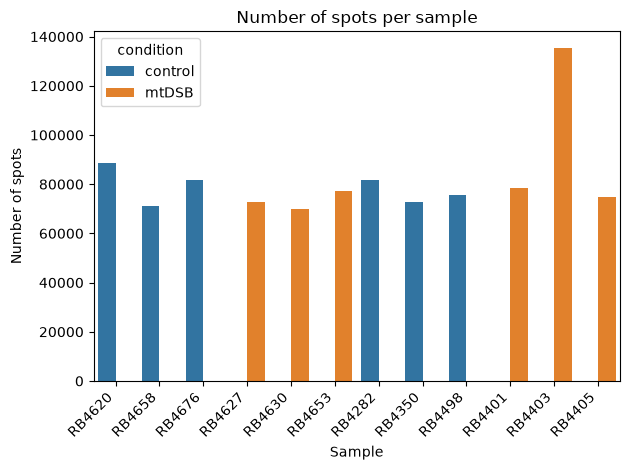

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sample_counts = adata.obs.groupby(["sample_id", "condition"], observed=True).size().reset_index(name="n_spots")

sns.barplot(data=sample_counts, x="sample_id", y="n_spots", hue="condition")

plt.xticks(rotation=45, ha="right")
plt.xlabel("Sample")
plt.ylabel("Number of spots")
plt.title("Number of spots per sample")
plt.tight_layout()
plt

In [14]:
print("Available obsm keys:", list(adata.obsm.keys()))
print("Available uns keys:", list(adata.uns.keys()))

Available obsm keys: ['X_mana_gauss', 'X_pca', 'X_scVI', 'X_umap', 'novae_latent', 'spatial']
Available uns keys: ['X_mana_gauss_params', '_scvi_manager_uuid', '_scvi_uuid', 'cytetype_annotation_leiden_3_colors', 'cytetype_jobDetails', 'cytetype_results', 'hvg', 'leiden_mana_0.1', 'leiden_mana_0.1_colors', 'leiden_mana_0.5', 'leiden_mana_0.5_colors', 'log1p', 'mana', 'novae_attrs', 'rank_genes_groups', 'spatial_neighbors']


In [33]:
def spatial_grid(metadata, sample_column="sample_id", condition="condition", obj=adata):

    # Get sample metadata
    sample_info = (
        obj.obs[[sample_column, condition]]
        .dropna()
        .drop_duplicates()
        .copy()
    )

    # Check that each sample has only one condition
    if sample_info[sample_column].duplicated().any():
        raise ValueError(
            "At least one sample is associated with multiple conditions."
        )

    # Order: control first, then mtDSB
    condition_order = ["control", "mtDSB"]

    sample_info["_order"] = pd.Categorical(
        sample_info[condition].astype(str),
        categories=condition_order,
        ordered=True
    )

    sample_info = sample_info.sort_values("_order")
    samples = sample_info[sample_column].tolist()

    print("Ordered samples:", samples)

    # Colors for conditions
    condition_colors = {
        "control": "#4C72B0",
        "mtDSB": "#DD8452"
    }

    # Consistent colors for metadata categories
    cell_classes = obj.obs[metadata].dropna().unique()

    cmap = plt.get_cmap("tab20", max(len(cell_classes), 1))
    cell_colors = {
        cell_class: cmap(i)
        for i, cell_class in enumerate(cell_classes)
    }

    # Grid: N rows x 3 columns
    ncols = 3
    nrows = math.ceil(len(samples) / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(16, 5 * nrows),
        squeeze=False
    )

    axes = axes.flatten()

    for i, sample in enumerate(samples):
        ax = axes[i]

        # Subset sample
        mask = obj.obs[sample_column] == sample
        obj_sample = obj[mask]

        coords = obj_sample.obsm["spatial"]
        classes = obj_sample.obs[metadata]

        # Plot each metadata category
        for cell_class in cell_classes:
            class_mask = classes.eq(cell_class).to_numpy()

            if not class_mask.any():
                continue

            ax.scatter(
                coords[class_mask, 0],
                coords[class_mask, 1],
                s=0.5,
                alpha=0.8,
                color=cell_colors[cell_class],
                rasterized=True
            )

        # Get sample condition
        sample_condition = sample_info.loc[
            sample_info[sample_column] == sample, condition
        ].iloc[0]

        ax.set_title(str(sample), fontsize=11)
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.set_xticks([])
        ax.set_yticks([])

        # Colored strip indicating condition
        ax.add_patch(
            mpatches.Rectangle(
                (-0.08, 0),
                0.035,
                1,
                transform=ax.transAxes,
                color=condition_colors[sample_condition],
                clip_on=False
            )
        )

    # Hide unused panels
    for i in range(len(samples), len(axes)):
        axes[i].axis("off")

    # Legend for metadata categories
    cell_handles = [
        mpatches.Patch(color=cell_colors[c], label=str(c))
        for c in cell_classes
    ]

    fig.legend(
        handles=cell_handles,
        title=metadata,
        loc="center left",
        bbox_to_anchor=(0.88, 0.5),
        frameon=False
    )

    # Legend for conditions
    condition_handles = [
        mpatches.Patch(color=color, label=cond)
        for cond, color in condition_colors.items()
    ]

    fig.legend(
        handles=condition_handles,
        title="Condition",
        loc="upper center",
        bbox_to_anchor=(0.5, 0.99),
        ncol=2,
        frameon=False
    )

    fig.suptitle(
        f"Spatial distribution of {metadata} by sample",
        fontsize=16,
        y=1.01
    )

    plt.tight_layout(rect=[0.04, 0, 0.86, 0.96])
    plt.show()

Ordered samples: ['RB4282', 'RB4350', 'RB4498', 'RB4620', 'RB4658', 'RB4676', 'RB4401', 'RB4403', 'RB4405', 'RB4627', 'RB4630', 'RB4653']


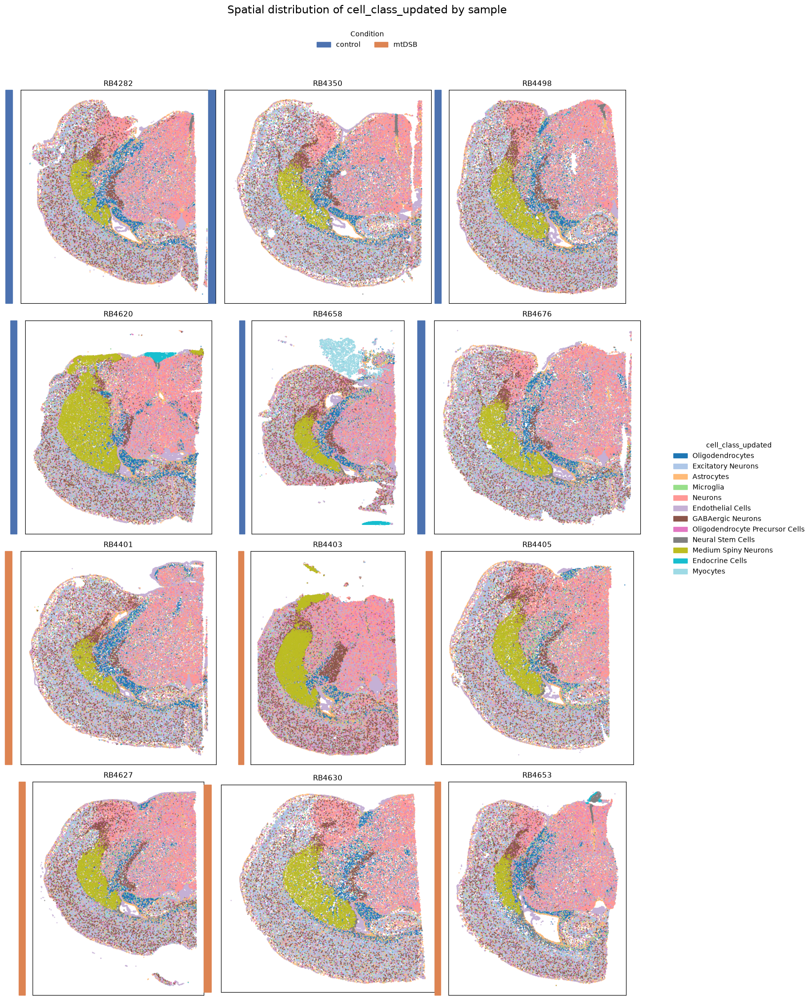

In [26]:
spatial_grid(metadata="cell_class_updated")

Ordered samples: ['RB4282', 'RB4350', 'RB4498', 'RB4620', 'RB4658', 'RB4676', 'RB4401', 'RB4403', 'RB4405', 'RB4627', 'RB4630', 'RB4653']


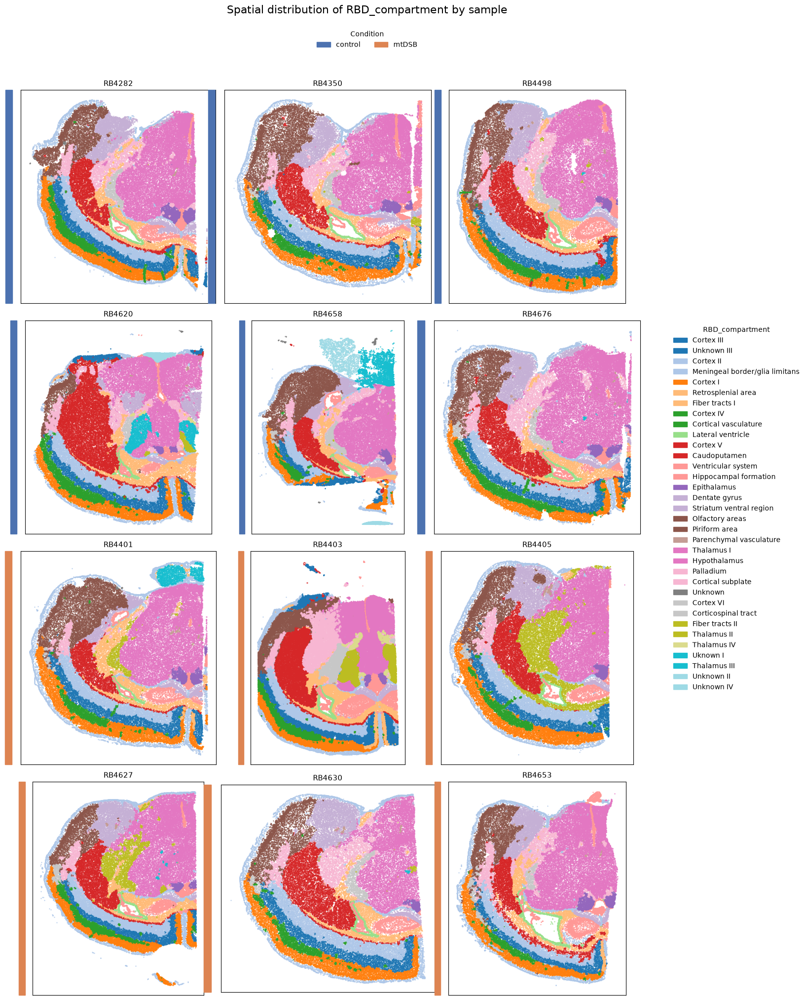

In [27]:
spatial_grid(metadata="RBD_compartment")

Ordered samples: ['RB4282', 'RB4350', 'RB4498', 'RB4620', 'RB4658', 'RB4676', 'RB4401', 'RB4403', 'RB4405', 'RB4627', 'RB4630', 'RB4653']


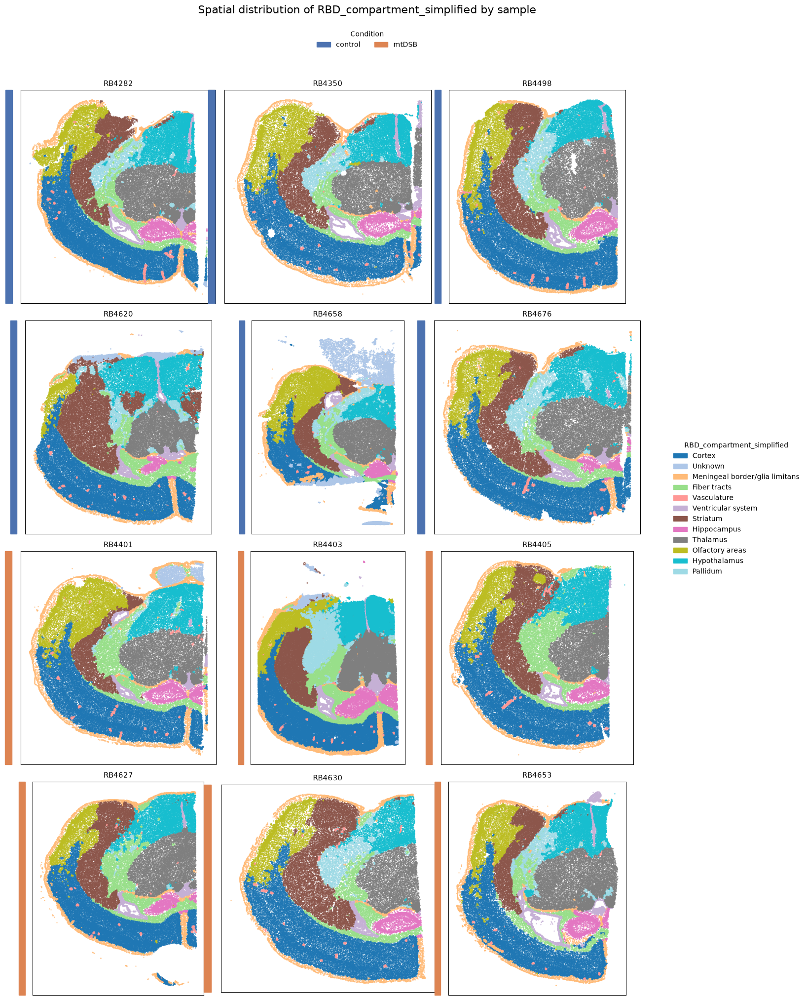

In [28]:
spatial_grid(metadata="RBD_compartment_simplified")

## Cellcharter compartment analysis

In [3]:
import cellcharter.gr
from cellcharter import gr, tl, pl

In [5]:
sq.gr.spatial_neighbors_delaunay(
    adata,
    spatial_key='spatial',
    library_key='sample_id',
    key_added='cc',
)
cc.gr.remove_long_links(adata, connectivity_key='cc', distances_key='cc')

INFO     Creating graph using `None` transform and `12` libraries.                                                 


In [6]:
cc.gr.aggregate_neighbors(
    adata, n_layers=3, use_rep='X_scVI',
    out_key='X_cellcharter', sample_key='sample_id',
    connectivity_key='cc'
)

  0%|          | 0/12 [00:00<?, ?it/s]

In [ ]:
autok = cc.tl.ClusterAutoK(n_clusters=(2, 15), max_runs=10, convergence_tol=0.001)
autok.fit(adata, use_rep='X_cellcharter')

cc.pl.autok_stability(autok)
print(autok.best_k)

adata.obs['compartment'] = autok.predict(adata, use_rep='X_cellcharter')
# or force a value: autok.predict(adata, use_rep='X_cellcharter', k=8)

14 [ 4  8 14]


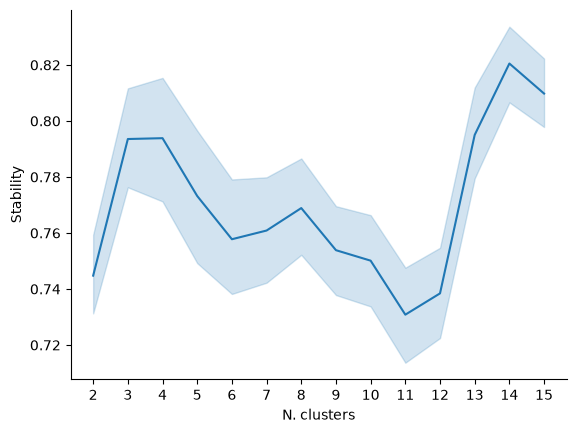

In [13]:
cc.pl.autok_stability(autok)
print(autok.best_k, autok.peaks)

In [14]:
adata.obs['compartment'] = autok.predict(adata, use_rep='X_cellcharter', k=14)
adata.obs['compartment'] = adata.obs['compartment'].astype(str).astype('category')

print(adata.obs['compartment'].nunique())   # should be 14

/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


14


/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/anitag/anaconda3/envs/ka

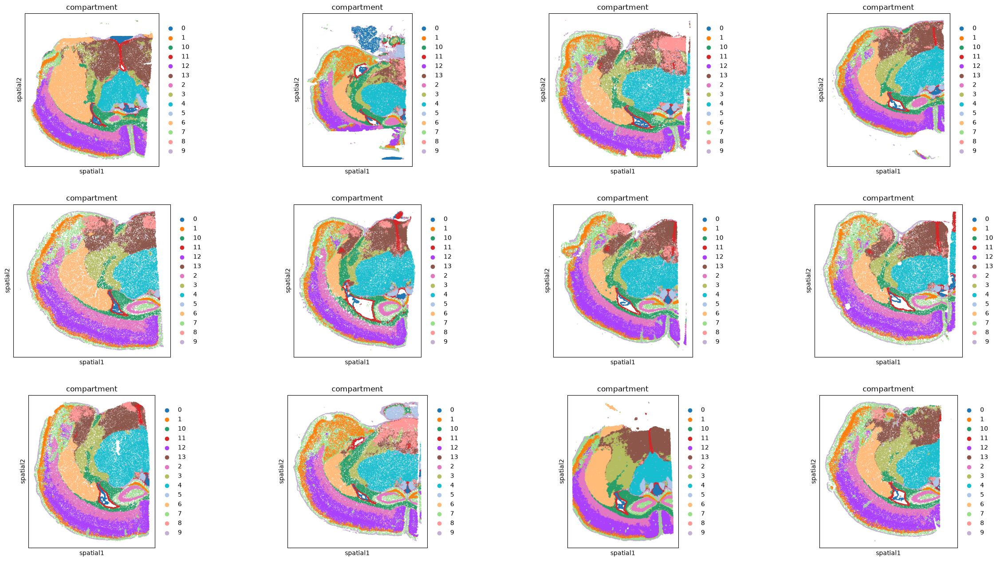

In [15]:
sq.pl.spatial_scatter(
    adata, color='compartment', library_key='sample_id', shape=None
)

In [16]:
# Fraction of each compartment's cells that comes from each sample
pd.crosstab(adata.obs['compartment'], adata.obs['sample_id'], normalize='index')

# Composition of each sample (often more informative)
pd.crosstab(adata.obs['sample_id'], adata.obs['compartment'], normalize='index')

compartment,0,1,10,11,12,13,2,3,4,5,6,7,8,9
sample_id,,,,,,,,,,,,,,
RB4620,0.052098,0.039417,0.065567,0.034784,0.162594,0.147422,0.082013,0.052977,0.085856,0.017550,0.177270,0.038583,0.005906,0.037963
RB4658,0.073106,0.112413,0.080987,0.036890,0.108999,0.041077,0.077967,0.055012,0.113129,0.027787,0.075818,0.089444,0.030723,0.076646
RB4676,0.017185,0.072923,0.061437,0.027288,0.164510,0.091245,0.080812,0.056704,0.121114,0.017821,0.084530,0.074513,0.089153,0.040767
RB4627,0.017090,0.066426,0.053577,0.030790,0.169435,0.134540,0.098712,0.063392,0.120278,0.014839,0.083352,0.070544,0.021442,0.055581
RB4630,0.008239,0.078312,0.052651,0.018194,0.181383,0.110852,0.115887,0.066096,0.090126,0.007266,0.115887,0.075809,0.035444,0.043855
RB4653,0.019108,0.077092,0.064561,0.059434,0.132073,0.127788,0.095734,0.039135,0.141912,0.022086,0.048547,0.080148,0.038604,0.053777
RB4282,0.012127,0.076431,0.059813,0.036967,0.185766,0.110449,0.093636,0.046279,0.123506,0.024278,0.061257,0.081558,0.040577,0.047356
RB4350,0.018110,0.070779,0.047181,0.045425,0.166404,0.133546,0.092058,0.045645,0.126453,0.015242,0.063796,0.099974,0.023117,0.052271
RB4498,0.014311,0.065318,0.053095,0.034595,0.163962,0.113933,0.121531,0.061222,0.133226,0.009435,0.081756,0.074898,0.035229,0.037489


In [17]:
pd.crosstab(adata.obs['condition'], adata.obs['compartment'], normalize='index')

compartment,0,1,10,11,12,13,2,3,4,5,6,7,8,9
condition,,,,,,,,,,,,,,
control,0.030989,0.071637,0.061342,0.035794,0.159662,0.107735,0.091095,0.052959,0.116462,0.018648,0.092973,0.075225,0.037434,0.048044
mtDSB,0.015482,0.074904,0.058748,0.032956,0.159118,0.118509,0.099371,0.070515,0.108283,0.020638,0.087429,0.074389,0.028942,0.050715


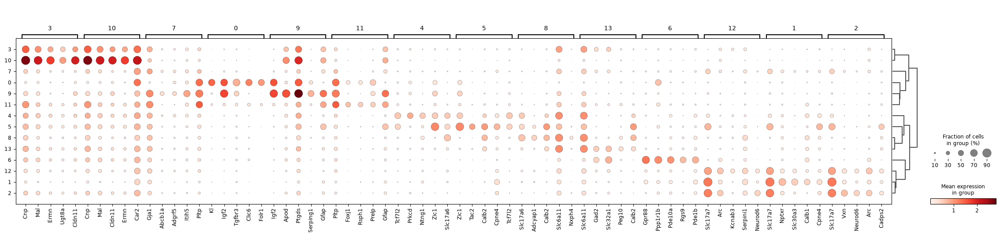

In [18]:
sc.tl.rank_genes_groups(adata, 'compartment', method='wilcoxon')
sc.pl.rank_genes_groups_dotplot(adata, n_genes=5)

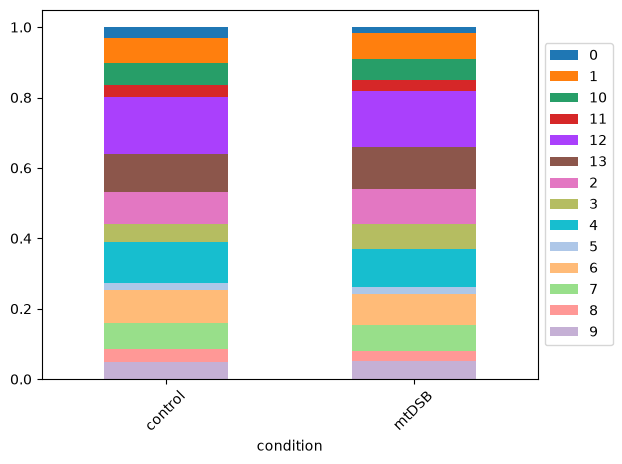

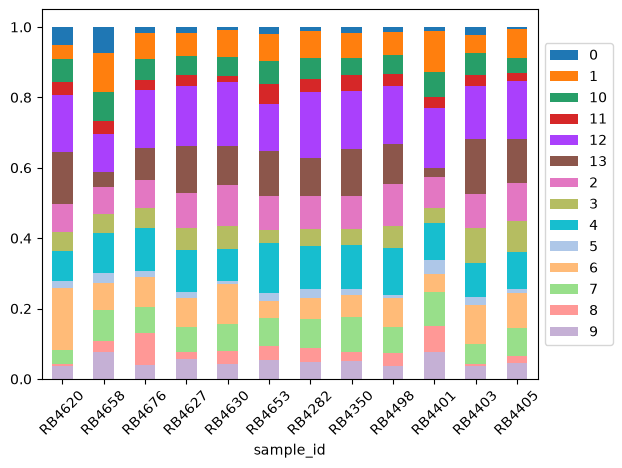

In [19]:
# Compartment proportions per condition (and per sample)
cc.pl.proportion(adata, group_key='condition', label_key='compartment')
cc.pl.proportion(adata, group_key='sample_id', label_key='compartment')

# Cell-type enrichment in each compartment (use your annotation column)
cc.gr.enrichment(adata, group_key='compartment', label_key='cell_type')

In [23]:
adata.write_h5ad('../data/adata_cellcharter.h5ad', compression='gzip')

In [24]:
autok.save('../data/autok_results')   # a directory path

/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/torchgmm/base/estimator/configurable.py:23: UserWarning: Failed to serialize fitted attributes of `GaussianMixture` to JSON. Falling back to `pickle`.
  super().save_attributes(path)


In [25]:
np.save('../data/autok_stability.npy', autok.stability)
print(autok.best_k, autok.peaks)

14 [ 4  8 14]


In [4]:
autok = cc.tl.ClusterAutoK.load('../data/autok_results')
print(autok.best_k, autok.peaks)

14 [ 4  8 14]


In [6]:
adata = ad.read_h5ad('../data/adata_cellcharter.h5ad')

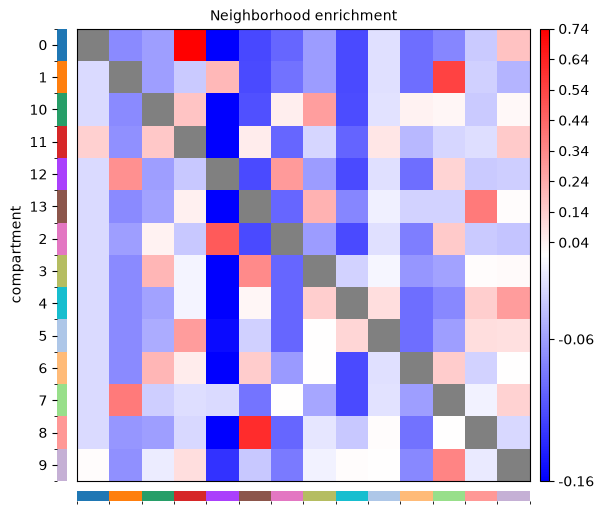

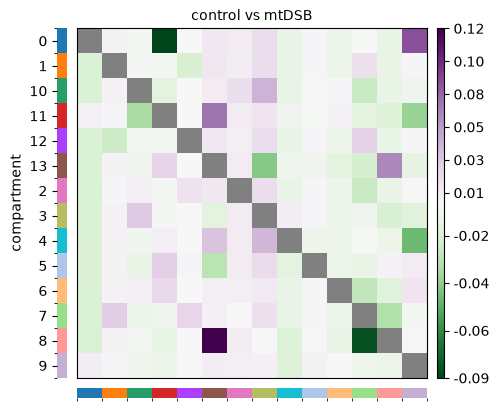

In [22]:
cc.gr.nhood_enrichment(adata, cluster_key='compartment', connectivity_key='cc')
cc.pl.nhood_enrichment(adata, cluster_key='compartment', figsize=(5, 5), dpi=100)
plt.savefig('../results/cellcharter/nhood_enrichment.png', dpi=150, bbox_inches='tight')

cc.gr.diff_nhood_enrichment(
    adata, cluster_key='compartment', condition_key='condition',
    connectivity_key='cc'
)
cc.pl.diff_nhood_enrichment(adata, cluster_key='compartment',
                            condition_key='condition')
plt.savefig('../results/cellcharter/diff_nhood_enrichment.png', dpi=150, bbox_inches='tight')

In [9]:
cc.tl.boundaries(adata, cluster_key='compartment')
cc.tl.linearity(adata, cluster_key='compartment')

/tmp/ipykernel_157554/1628990931.py:2: FutureWarning: linearity is deprecated and will be removed in the next release. Please use `linearity_metric` instead.
  cc.tl.linearity(adata, cluster_key='compartment')


### Some plots

In [11]:
SAMPLE, COND, COMP, CT = 'sample_id', 'condition', 'compartment', 'cell_class_updated'

In [ ]:
adata.obs['sample_cond'] = (adata.obs[COND].astype(str) + ' | ' +
                            adata.obs[SAMPLE].astype(str)).astype('category')

sq.pl.spatial_scatter(
    adata, color=COMP, library_key='sample_cond', shape=None,
    ncols=4, figsize=(4, 4), size=3
)
plt.savefig('../results/cellcharter/spatial_compartments.png', dpi=150, bbox_inches='tight')

In [ ]:
for c in adata.obs[COND].unique():
    sub = adata[adata.obs[COND] == c]
    sq.pl.spatial_scatter(sub, color=COMP, library_key='sample_cond',
                          shape=None, ncols=3, figsize=(4, 4), size=3)
    plt.savefig(f'../results/cellcharter/spatial_compartments_{c}.png', dpi=150, bbox_inches='tight')

In [15]:
sc.tl.rank_genes_groups(adata, COMP, method='wilcoxon')   # adata.X should be log-normalized

df = sc.get.rank_genes_groups_df(adata, group=None)
df = df[(df['logfoldchanges'] > 0) & (df['pvals_adj'] < 0.05)]

top = (df.sort_values(['group', 'scores'], ascending=[True, False])
         .groupby('group').head(10))

for g, sub in top.groupby('group', observed=True):
    print(f"Compartment {g}: " + ', '.join(sub['names']))

top.to_csv('../results/cellcharter/markers_top10_per_compartment.csv', index=False)

Compartment 0: Kl, Igf2, Tgfbr3, Clic6, Folr1, Cab39l, Gpc4, Sulf1, Sostdc1, Cldn2
Compartment 1: Slc17a7, Nptxr, Slc30a3, Calb1, Cpne4, Bdnf, Lypd1, Igfn1, Gpc4, Otof
Compartment 10: Cnp, Mal, Cldn11, Ermn, Car2, Mog, Ptgds, Ugt8a, Mag, Apod
Compartment 11: Pltp, Foxj1, Rsph1, Prelp, Gfap, Gja1, Drc7, Cnp, Slc2a1, Clic6
Compartment 12: Slc17a7, Arc, Kcnab3, Serpini1, Neurod6, Vxn, Cadps2, Slc30a3, Fos, Nefm
Compartment 13: Slc6a11, Gad2, Slc32a1, Peg10, Calb2, Gad1, Ecel1, Gpr101, Dlk1, Glra1
Compartment 2: Slc17a7, Vxn, Neurod6, Arc, Cadps2, Crym, Bdnf, Serpini1, Cpne4, Nptxr
Compartment 3: Cnp, Mal, Ermn, Ugt8a, Cldn11, Car2, Ptgds, Gfap, Mog, Slc6a11
Compartment 4: Tcf7l2, Prkcd, Ntng1, Zic1, Slc17a6, Synpo2, Ramp3, Slc6a11, Kcnc2, Nefh
Compartment 5: Zic1, Tac2, Calb2, Cpne4, Tcf7l2, Cadps2, Nptx2, Slc17a6, Nefh, Gfap
Compartment 6: Gpr88, Ppp1r1b, Pde10a, Rgs9, Pde1b, Scn4b, Slc32a1, Actn2, Adora2a, Gad2
Compartment 7: Gja1, Abcb1a, Adgrf5, Itih5, Pltp, Slc2a1, Car2, P2ry12, Fn1,

/tmp/ipykernel_157554/1197597336.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('group').head(10))


cell_class_updated  Astrocytes  Endocrine Cells  Endothelial Cells  Excitatory Neurons  GABAergic Neurons  Medium Spiny Neurons  Microglia  Myocytes  Neural Stem Cells  Neurons  Oligodendrocyte Precursor Cells  Oligodendrocytes
compartment                                                                                                                                                                                                                        
0                        0.012            0.215              0.680               0.000              0.000                 0.000      0.000     0.089              0.002    0.001                            0.000             0.000
1                        0.086            0.000              0.009               0.831              0.009                 0.000      0.031     0.000              0.001    0.016                            0.013             0.005
10                       0.138            0.000              0.051               0.000  

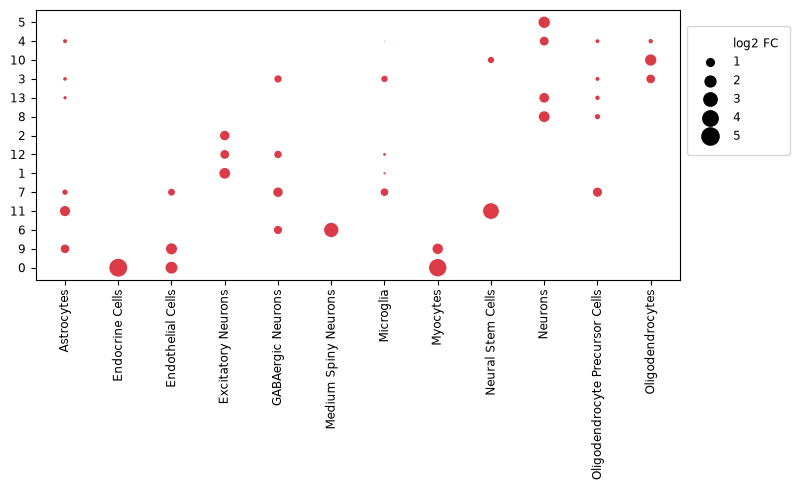

In [18]:
# Composition: for each compartment, fraction of each cell type
comp = pd.crosstab(adata.obs[COMP], adata.obs[CT], normalize='index').round(3)
print(comp.to_string())
comp.to_csv('../results/cellcharter/celltype_fraction_per_compartment.csv')

# Enrichment (log2 fold change vs. the overall frequency)
cc.gr.enrichment(adata, group_key=COMP, label_key=CT)
enr = adata.uns[f'{COMP}_{CT}_enrichment']['enrichment']
print(enr.round(2).to_string())
enr.to_csv('../results/cellcharter/celltype_enrichment_per_compartment.csv')

cc.pl.enrichment(adata, group_key=COMP, label_key=CT, figsize=(7, 5))
plt.savefig('../results/cellcharter/celltype_enrichment.png', dpi=150, bbox_inches='tight')

In [19]:
cond = pd.crosstab(adata.obs[COND], adata.obs[COMP], normalize='index').round(3)
print(cond.to_string())

compartment      0      1     10     11     12     13      2      3      4      5      6      7      8      9
condition                                                                                                    
control      0.031  0.072  0.061  0.036  0.160  0.108  0.091  0.053  0.116  0.019  0.093  0.075  0.037  0.048
mtDSB        0.015  0.075  0.059  0.033  0.159  0.119  0.099  0.071  0.108  0.021  0.087  0.074  0.029  0.051


#### Testing compartment proportions
Testing different proportions of compartments in control vs condition. No significance found for any compartment

In [20]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

prop = pd.crosstab(adata.obs[SAMPLE], adata.obs[COMP], normalize='index')
cond = adata.obs[[SAMPLE, COND]].drop_duplicates().set_index(SAMPLE)[COND]
ctrl, mut = cond[cond == 'control'].index, cond[cond == 'mtDSB'].index

res = pd.DataFrame({
    'control': prop.loc[ctrl].mean(),
    'mtDSB': prop.loc[mut].mean(),
    'p': [mannwhitneyu(prop.loc[ctrl, c], prop.loc[mut, c]).pvalue for c in prop.columns],
})
res['padj'] = multipletests(res['p'], method='fdr_bh')[1]
print(res.round(3).to_string())

             control  mtDSB      p   padj
compartment                              
0              0.031  0.014  0.240  0.919
1              0.073  0.078  0.394  0.919
10             0.061  0.058  0.818  0.937
11             0.036  0.033  0.180  0.919
12             0.159  0.161  0.699  0.937
13             0.106  0.114  0.589  0.937
2              0.091  0.100  0.132  0.919
3              0.053  0.067  0.394  0.919
4              0.117  0.110  0.394  0.919
5              0.019  0.020  0.937  0.937
6              0.091  0.085  0.937  0.937
7              0.076  0.077  0.818  0.937
8              0.037  0.032  0.699  0.937
9              0.049  0.052  0.485  0.937


#### Testing microglia fraction per compartment per sample
No significat difference. But the distributions of comparments 3, 8, a bit 10 are different, with 3 being the most skewed one, and not driven by a single sample. Non significance could be caused by the rank-based test (looks at order and not values). This was chosen beacuse of few replicates and robustness to outlier sections.

   compartment  n_ctrl  n_mut  control   mtDSB       p    padj
0            0       6      6   0.0003  0.0004  0.5497  0.8157
1            1       6      6   0.0332  0.0294  0.0931  0.3258
2           10       6      6   0.0236  0.0303  0.5887  0.8157
3           11       6      6   0.0161  0.0203  0.2403  0.5606
4           12       6      6   0.0332  0.0316  0.3939  0.7879
5           13       6      6   0.0216  0.0230  0.6991  0.8157
6            2       6      6   0.0310  0.0285  0.0649  0.3030
7            3       6      6   0.0339  0.0571  0.0649  0.3030
8            4       6      6   0.0266  0.0337  0.6991  0.8157
9            5       6      6   0.0085  0.0092  0.8182  0.8811
10           6       6      6   0.0279  0.0280  1.0000  1.0000
11           7       6      6   0.0580  0.0585  0.6991  0.8157
12           8       6      6   0.0171  0.0222  0.0043  0.0606
13           9       6      6   0.0087  0.0119  0.1320  0.3697


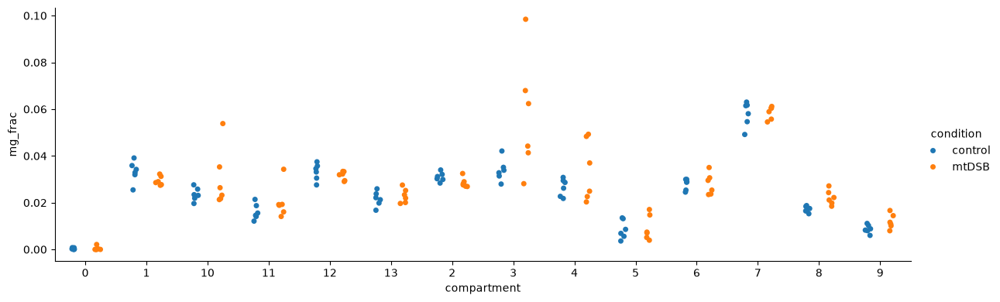

In [23]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import seaborn as sns

n  = adata.obs.groupby([SAMPLE, COMP], observed=True).size()
mg = (adata.obs[adata.obs[CT] == 'Microglia']
        .groupby([SAMPLE, COMP], observed=True).size()
        .reindex(n.index, fill_value=0))      # real zeros where the compartment exists

MIN_CELLS = 100                                # ignore sample/compartment pairs with few cells
frac = (mg / n).where(n >= MIN_CELLS).unstack()   # NaN = absent or too small

cond = adata.obs[[SAMPLE, COND]].drop_duplicates().set_index(SAMPLE)[COND]
ctrl, mut = cond[cond == 'control'].index, cond[cond == 'mtDSB'].index

rows = []
for c in frac.columns:
    a = frac.loc[frac.index.isin(ctrl), c].dropna()
    b = frac.loc[frac.index.isin(mut), c].dropna()
    if len(a) >= 3 and len(b) >= 3:
        rows.append((c, len(a), len(b), a.mean(), b.mean(), mannwhitneyu(a, b).pvalue))

res = pd.DataFrame(rows, columns=['compartment', 'n_ctrl', 'n_mut', 'control', 'mtDSB', 'p'])
res['padj'] = multipletests(res['p'], method='fdr_bh')[1]
print(res.round(4).to_string())

long = frac.stack().rename('mg_frac').reset_index()
long[COND] = long[SAMPLE].map(cond)
sns.catplot(data=long, x=COMP, y='mg_frac', hue=COND, kind='strip',
            dodge=True, height=4, aspect=3)
plt.savefig('../results/cellcharter/microglia_fraction.png', dpi=150, bbox_inches='tight')

In [ ]:
# giving provisory names to compartments, check with Leslie
COMP = 'compartment'

names = {
    '0':  'Choroid plexus',
    '1':  'Cortex L2/3?',
    '12': 'Cortex mid layers',
    '2':  'Cortex deep layers',
    '10': 'White matter (corpus callosum)',
    '3':  'Myelinated fiber tracts (mixed)',
    '6':  'Striatum',
    '4':  'Thalamus',
    '5':  'Habenula?',
    '13': 'Hypothalamus? (GABAergic)',
    '8':  'Subcortical glutamatergic nucleus?',
    '11': 'Ependyma / ventricle lining',
    '7':  'Vascular-glial rich (subpial, fissures)',
    '9':  'Meninges / pia',
}

# Finer name for display; the numeric labels stay the key for the stored CellCharter results
cats = list(adata.obs[COMP].cat.categories)
old_col = dict(zip(cats, adata.uns[f'{COMP}_colors']))
order = [names[k] for k in names]          # display order

adata.obs['cc_compartment_name'] = pd.Categorical(
    adata.obs[COMP].astype(str).map(names), categories=order)
adata.uns['cc_compartment_name_colors'] = [old_col[k] for k in names]

sq.pl.spatial_scatter(adata, color='cc_compartment_name', library_key='sample_id',
                      shape=None, ncols=4, figsize=(4, 4), size=3)

Ordered samples: ['RB4282', 'RB4350', 'RB4498', 'RB4620', 'RB4658', 'RB4676', 'RB4401', 'RB4403', 'RB4405', 'RB4627', 'RB4630', 'RB4653']


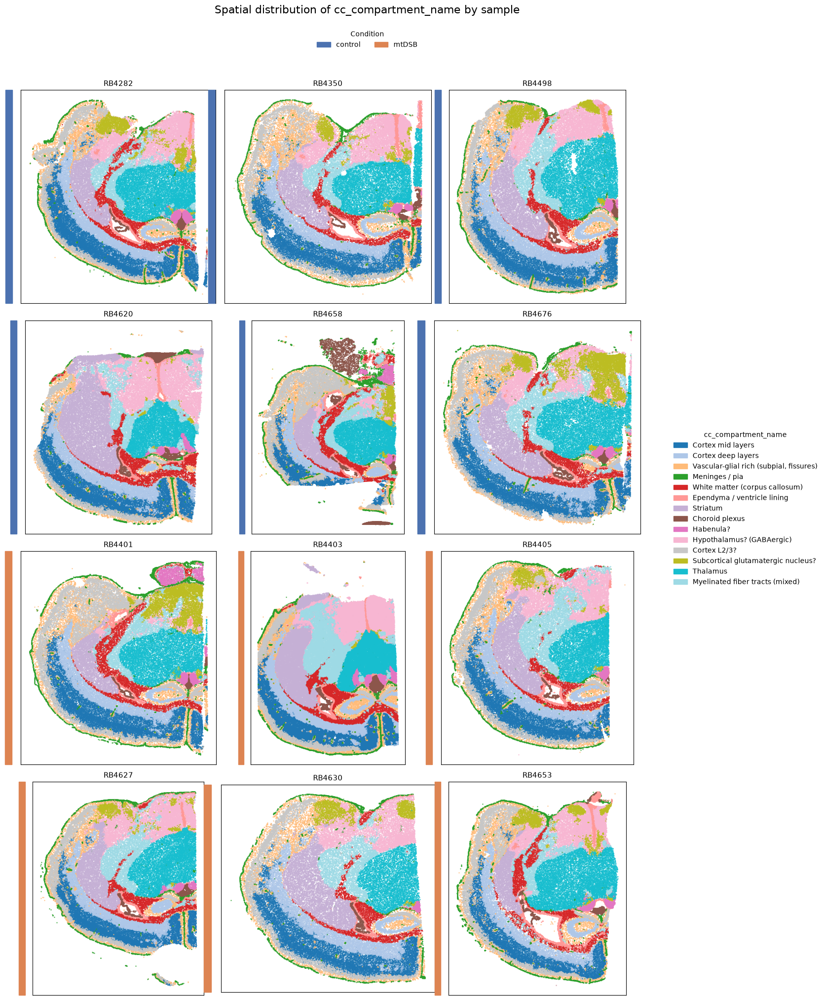

In [34]:
spatial_grid(metadata = "cc_compartment_name")

RB4403 is the sample with double the cells